# Synthetic Facility Load Profile

No site-specific interval data are available for this hypothetical project, so I create a reproducible 8,760-hour facility load profile. The profile represents a 100 MW data center with an average demand of 85 MW. It is a screening input designed to support scenario comparisons, not a forecast of an actual facility.

## Modeling choices

I assume a consistently high load with modest hourly and seasonal variation. Demand is highest in the late afternoon and during the summer, with a small weekend reduction and random hourly variation. A fixed random seed makes the profile reproducible. The resulting load is normalized to an 85 MW annual average and constrained to remain below the 100 MW design capacity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)
idx = pd.date_range("2025-01-01", periods=8760, freq="h")
hour = idx.hour.to_numpy()
day = idx.dayofyear.to_numpy()
weekday = idx.dayofweek.to_numpy()

shape = (
    1.0
    + 0.018 * np.cos(2 * np.pi * (hour - 16) / 24)
    + 0.025 * np.cos(2 * np.pi * (day - 200) / 365)
    - 0.008 * (weekday >= 5)
    + rng.normal(0, 0.006, len(idx))
)

target_average_mw = 85.0
load = target_average_mw * shape / shape.mean()

# Compress deviations if needed so the maximum remains below 100 MW.
if load.max() > 99.0:
    scale = (99.0 - target_average_mw) / (load.max() - target_average_mw)
    load = target_average_mw + (load - target_average_mw) * scale

facility = pd.DataFrame({"timestamp": idx, "load_mw": load})
facility.to_csv(PROCESSED / "facility_load_hourly.csv", index=False)

assert len(facility) == 8760
assert facility["timestamp"].is_unique
assert facility["load_mw"].between(0, 100).all()
assert abs(facility["load_mw"].mean() - 85.0) < 0.1
facility.describe()


,timestamp,load_mw
count,8760,8760.000000
mean,2025-07-02 11:30:00,85.000000
min,2025-01-01 00:00:00,79.638114
25%,2025-04-02 05:45:00,83.578802
50%,2025-07-02 11:30:00,84.991991
75%,2025-10-01 17:15:00,86.416594
max,2025-12-31 23:00:00,90.199365
std,NaN,1.955626


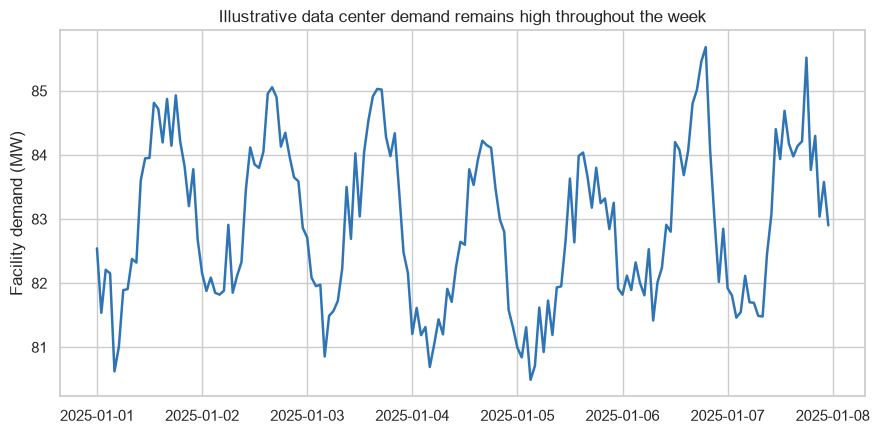

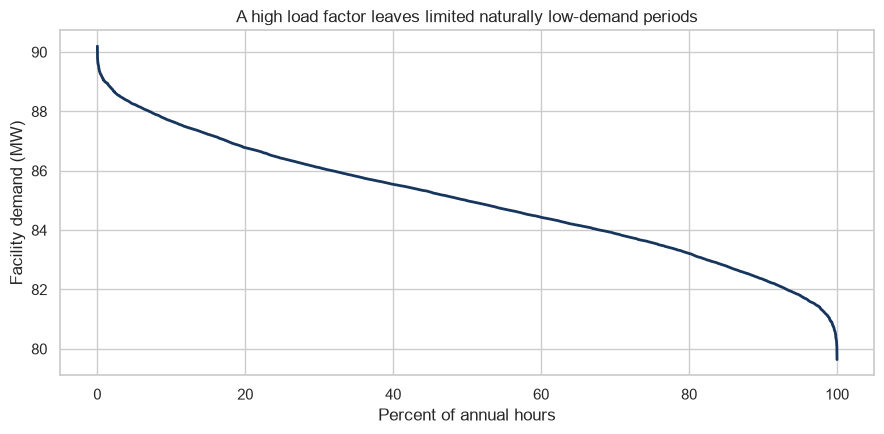

In [2]:
sns.set_theme(style="whitegrid")

week = facility.iloc[:168]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(week["timestamp"], week["load_mw"], color="#2F75B5", linewidth=1.8)
ax.set(title="Illustrative data center demand remains high throughout the week",
       xlabel="", ylabel="Facility demand (MW)")
fig.tight_layout()
fig.savefig(FIGURES / "facility_load_week.png", dpi=300, bbox_inches="tight")

duration = facility["load_mw"].sort_values(ascending=False).reset_index(drop=True)
x = 100 * np.arange(1, len(duration) + 1) / len(duration)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, duration, color="#17365D", linewidth=2)
ax.set(title="A high load factor leaves limited naturally low-demand periods",
       xlabel="Percent of annual hours", ylabel="Facility demand (MW)")
fig.tight_layout()
fig.savefig(FIGURES / "load_duration_curve.png", dpi=300, bbox_inches="tight")


## Interpretation

The synthetic facility averages 85 MW and reaches an annual peak of approximately 90.2 MW. Its average load is therefore about 94% of its observed annual peak, indicating a much flatter and more continuous demand profile than a typical office or retail building.

The load-duration curve reinforces this point: there are relatively few naturally low-demand hours. That characteristic matters for grid planning and demand-charge management because the facility places sustained demand on generation, transmission, and distribution infrastructure. I use this hourly profile as the common baseline for testing efficiency, clean procurement, flexible operations, and battery peak shaving.